In [1]:

# imports
import os
import sys
import types
import json
import base64

# figure size/format
fig_width = 7
fig_height = 5
fig_format = 'retina'
fig_dpi = 96
interactivity = ''
is_shiny = False
is_dashboard = False
plotly_connected = True

# matplotlib defaults / format
try:
  import matplotlib.pyplot as plt
  plt.rcParams['figure.figsize'] = (fig_width, fig_height)
  plt.rcParams['figure.dpi'] = fig_dpi
  plt.rcParams['savefig.dpi'] = "figure"

  # IPython 7.14 deprecated set_matplotlib_formats from IPython
  try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
  except ImportError:
    # Fall back to deprecated location for older IPython versions
    from IPython.display import set_matplotlib_formats
    
  set_matplotlib_formats(fig_format)
except Exception:
  pass

# plotly use connected mode
try:
  import plotly.io as pio
  if plotly_connected:
    pio.renderers.default = "notebook_connected"
  else:
    pio.renderers.default = "notebook"
  for template in pio.templates.keys():
    pio.templates[template].layout.margin = dict(t=30,r=0,b=0,l=0)
except Exception:
  pass

# disable itables paging for dashboards
if is_dashboard:
  try:
    from itables import options
    options.dom = 'fiBrtlp'
    options.maxBytes = 1024 * 1024
    options.language = dict(info = "Showing _TOTAL_ entries")
    options.classes = "display nowrap compact"
    options.paging = False
    options.searching = True
    options.ordering = True
    options.info = True
    options.lengthChange = False
    options.autoWidth = False
    options.responsive = True
    options.keys = True
    options.buttons = []
  except Exception:
    pass
  
  try:
    import altair as alt
    # By default, dashboards will have container sized
    # vega visualizations which allows them to flow reasonably
    theme_sentinel = '_quarto-dashboard-internal'
    def make_theme(name):
        nonTheme = alt.themes._plugins[name]    
        def patch_theme(*args, **kwargs):
            existingTheme = nonTheme()
            if 'height' not in existingTheme:
              existingTheme['height'] = 'container'
            if 'width' not in existingTheme:
              existingTheme['width'] = 'container'

            if 'config' not in existingTheme:
              existingTheme['config'] = dict()
            
            # Configure the default font sizes
            title_font_size = 15
            header_font_size = 13
            axis_font_size = 12
            legend_font_size = 12
            mark_font_size = 12
            tooltip = False

            config = existingTheme['config']

            # The Axis
            if 'axis' not in config:
              config['axis'] = dict()
            axis = config['axis']
            if 'labelFontSize' not in axis:
              axis['labelFontSize'] = axis_font_size
            if 'titleFontSize' not in axis:
              axis['titleFontSize'] = axis_font_size  

            # The legend
            if 'legend' not in config:
              config['legend'] = dict()
            legend = config['legend']
            if 'labelFontSize' not in legend:
              legend['labelFontSize'] = legend_font_size
            if 'titleFontSize' not in legend:
              legend['titleFontSize'] = legend_font_size  

            # The header
            if 'header' not in config:
              config['header'] = dict()
            header = config['header']
            if 'labelFontSize' not in header:
              header['labelFontSize'] = header_font_size
            if 'titleFontSize' not in header:
              header['titleFontSize'] = header_font_size    

            # Title
            if 'title' not in config:
              config['title'] = dict()
            title = config['title']
            if 'fontSize' not in title:
              title['fontSize'] = title_font_size

            # Marks
            if 'mark' not in config:
              config['mark'] = dict()
            mark = config['mark']
            if 'fontSize' not in mark:
              mark['fontSize'] = mark_font_size

            # Mark tooltips
            if tooltip and 'tooltip' not in mark:
              mark['tooltip'] = dict(content="encoding")

            return existingTheme
            
        return patch_theme

    # We can only do this once per session
    if theme_sentinel not in alt.themes.names():
      for name in alt.themes.names():
        alt.themes.register(name, make_theme(name))
      
      # register a sentinel theme so we only do this once
      alt.themes.register(theme_sentinel, make_theme('default'))
      alt.themes.enable('default')

  except Exception:
    pass

# enable pandas latex repr when targeting pdfs
try:
  import pandas as pd
  if fig_format == 'pdf':
    pd.set_option('display.latex.repr', True)
except Exception:
  pass

# interactivity
if interactivity:
  from IPython.core.interactiveshell import InteractiveShell
  InteractiveShell.ast_node_interactivity = interactivity

# NOTE: the kernel_deps code is repeated in the cleanup.py file
# (we can't easily share this code b/c of the way it is run).
# If you edit this code also edit the same code in cleanup.py!

# output kernel dependencies
kernel_deps = dict()
for module in list(sys.modules.values()):
  # Some modules play games with sys.modules (e.g. email/__init__.py
  # in the standard library), and occasionally this can cause strange
  # failures in getattr.  Just ignore anything that's not an ordinary
  # module.
  if not isinstance(module, types.ModuleType):
    continue
  path = getattr(module, "__file__", None)
  if not path:
    continue
  if path.endswith(".pyc") or path.endswith(".pyo"):
    path = path[:-1]
  if not os.path.exists(path):
    continue
  kernel_deps[path] = os.stat(path).st_mtime
print(json.dumps(kernel_deps))

# set run_path if requested
run_path = 'L1VzZXJzL3dpbGx0aG9tcHNvbi9Eb2N1bWVudHMvQ1NEUy9zaWRlX3Byb2plY3RzL2hldGVyb2dlbmVvdXMtaW5mZWN0aW9uLWtlcm5lbHMvbm90ZWJvb2tzL3dpbGw='
if run_path:
  # hex-decode the path
  run_path = base64.b64decode(run_path.encode("utf-8")).decode("utf-8")
  os.chdir(run_path)

# reset state
%reset

# shiny
# Checking for shiny by using False directly because we're after the %reset. We don't want
# to set a variable that stays in global scope.
if False:
  try:
    import htmltools as _htmltools
    import ast as _ast

    _htmltools.html_dependency_render_mode = "json"

    # This decorator will be added to all function definitions
    def _display_if_has_repr_html(x):
      try:
        # IPython 7.14 preferred import
        from IPython.display import display, HTML
      except:
        from IPython.core.display import display, HTML

      if hasattr(x, '_repr_html_'):
        display(HTML(x._repr_html_()))
      return x

    # ideally we would undo the call to ast_transformers.append
    # at the end of this block whenver an error occurs, we do 
    # this for now as it will only be a problem if the user 
    # switches from shiny to not-shiny mode (and even then likely
    # won't matter)
    import builtins
    builtins._display_if_has_repr_html = _display_if_has_repr_html

    class _FunctionDefReprHtml(_ast.NodeTransformer):
      def visit_FunctionDef(self, node):
        node.decorator_list.insert(
          0,
          _ast.Name(id="_display_if_has_repr_html", ctx=_ast.Load())
        )
        return node

      def visit_AsyncFunctionDef(self, node):
        node.decorator_list.insert(
          0,
          _ast.Name(id="_display_if_has_repr_html", ctx=_ast.Load())
        )
        return node

    ip = get_ipython()
    ip.ast_transformers.append(_FunctionDefReprHtml())

  except:
    pass

def ojs_define(**kwargs):
  import json
  try:
    # IPython 7.14 preferred import
    from IPython.display import display, HTML
  except:
    from IPython.core.display import display, HTML

  # do some minor magic for convenience when handling pandas
  # dataframes
  def convert(v):
    try:
      import pandas as pd
    except ModuleNotFoundError: # don't do the magic when pandas is not available
      return v
    if type(v) == pd.Series:
      v = pd.DataFrame(v)
    if type(v) == pd.DataFrame:
      j = json.loads(v.T.to_json(orient='split'))
      return dict((k,v) for (k,v) in zip(j["index"], j["data"]))
    else:
      return v

  v = dict(contents=list(dict(name=key, value=convert(value)) for (key, value) in kwargs.items()))
  display(HTML('<script type="ojs-define">' + json.dumps(v) + '</script>'), metadata=dict(ojs_define = True))
globals()["ojs_define"] = ojs_define
globals()["__spec__"] = None

{"/opt/homebrew/Cellar/python@3.13/3.13.3_1/Frameworks/Python.framework/Versions/3.13/lib/python3.13/importlib/_bootstrap.py": 1744120448.0, "/opt/homebrew/Cellar/python@3.13/3.13.3_1/Frameworks/Python.framework/Versions/3.13/lib/python3.13/importlib/_bootstrap_external.py": 1744120448.0, "/opt/homebrew/Cellar/python@3.13/3.13.3_1/Frameworks/Python.framework/Versions/3.13/lib/python3.13/zipimport.py": 1744120448.0, "/opt/homebrew/Cellar/python@3.13/3.13.3_1/Frameworks/Python.framework/Versions/3.13/lib/python3.13/codecs.py": 1744120448.0, "/opt/homebrew/Cellar/python@3.13/3.13.3_1/Frameworks/Python.framework/Versions/3.13/lib/python3.13/encodings/aliases.py": 1744120448.0, "/opt/homebrew/Cellar/python@3.13/3.13.3_1/Frameworks/Python.framework/Versions/3.13/lib/python3.13/encodings/__init__.py": 1744120448.0, "/opt/homebrew/Cellar/python@3.13/3.13.3_1/Frameworks/Python.framework/Versions/3.13/lib/python3.13/encodings/utf_8.py": 1744120448.0, "/opt/homebrew/Cellar/python@3.13/3.13.3_1/Fr

In [2]:
#| label: setup
#| echo: false
import sys
sys.path.insert(0, "../..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path
from src.fig_styles import set_publication_style, PALETTE_MUTED, WIDTH_SINGLE, WIDTH_DOUBLE, HEIGHT_STD

set_publication_style()

RESULTS = Path("../../results/simplicity_test")

Publication style set with 9 colors in cycle (constrained_layout=False).


In [3]:
#| label: load-metadata
import json

with open(RESULTS / "metadata.json") as f:
    meta = json.load(f)

print(f"V={meta['V']}, kmax={meta['kmax']}, γ={meta['GAMMA']}, T={meta['TMAX']}")
print(f"Exp 1: β={meta['BETA']} (homogeneous simple contagion)")
print(f"Exp 2: ρ_l={meta['RHO_L']}, ρ_h={meta['RHO_H']}, w={meta['W']}, k0={meta['K0']} (sigmoid)")
print(f"Exp 3: β₁={meta['BETA_1']}, β₂={meta['BETA_2']} (two-block mixture)")

V=300, kmax=25, γ=0.15, T=200
Exp 1: β=0.08 (homogeneous simple contagion)
Exp 2: ρ_l=0.02, ρ_h=0.5, w=1.5, k0=4.0 (sigmoid)
Exp 3: β₁=0.04, β₂=0.2 (two-block mixture)


In [4]:
#| label: load-posteriors
def load_mu_samples(experiment, model):
    """Load non-parametric kernel mode posterior samples (mu[1] for K=1)."""
    path = RESULTS / experiment / model / "posterior_samples.parquet"
    draws = pd.read_parquet(path)
    mu_cols = sorted([c for c in draws.columns if c.startswith("mu[1,")],
                     key=lambda c: int(c.split(",")[1].rstrip("]")))
    mu_samples = draws[mu_cols].values
    return mu_samples, draws

def load_rho_samples(experiment):
    """Load simple contagion rho posterior samples."""
    path = RESULTS / experiment / "simple_contagion" / "posterior_samples.parquet"
    draws = pd.read_parquet(path)
    rho = draws["rho[1]"].values
    return rho

# Non-parametric monotonic posteriors
mu_np_exp1, _ = load_mu_samples("experiment_1_homogeneous", "non_parametric_monotonic")
mu_np_exp2, _ = load_mu_samples("experiment_2_sigmoid", "non_parametric_monotonic")
mu_np_exp3, _ = load_mu_samples("experiment_3_mixture", "non_parametric_monotonic")

# Simple contagion rho posteriors
rho_exp1 = load_rho_samples("experiment_1_homogeneous")
rho_exp2 = load_rho_samples("experiment_2_sigmoid")
rho_exp3 = load_rho_samples("experiment_3_mixture")

kmax = meta["kmax"]
nu = np.arange(1, kmax + 1)

print(f"Loaded {mu_np_exp1.shape[0]} samples per experiment (kmax={kmax})")
print(f"  Exp 1: ρ̂ = {rho_exp1.mean():.4f} (truth: {meta['BETA']})")
print(f"  Exp 2: ρ̂ = {rho_exp2.mean():.4f} (best simple fit to sigmoid)")
print(f"  Exp 3: ρ̂ = {rho_exp3.mean():.4f} (best simple fit to mixture)")

Loaded 1000 samples per experiment (kmax=25)
  Exp 1: ρ̂ = 0.0811 (truth: 0.08)
  Exp 2: ρ̂ = 0.0620 (best simple fit to sigmoid)
  Exp 3: ρ̂ = 0.0879 (best simple fit to mixture)


In [5]:
#| label: mahalanobis
def compute_mahalanobis_distances(mu_samples, rho_samples):
    """
    Compute Mahalanobis distance between each non-parametric sample and
    the simple contagion reference kernel.
    """
    n_samples, kmax = mu_samples.shape
    nu = np.arange(1, kmax + 1)

    Sigma = np.cov(mu_samples, rowvar=False)
    Sigma += 1e-8 * np.eye(kmax)
    L = np.linalg.cholesky(Sigma)

    rho_hat = np.mean(rho_samples)
    mu_sc = 1.0 - (1.0 - rho_hat) ** nu

    D_M = np.zeros(n_samples)
    for s in range(n_samples):
        diff = mu_samples[s] - mu_sc
        z = np.linalg.solve(L, diff)
        D_M[s] = z @ z

    return D_M, mu_sc, Sigma

D_M_exp1, mu_sc_exp1, _ = compute_mahalanobis_distances(mu_np_exp1, rho_exp1)
D_M_exp2, mu_sc_exp2, _ = compute_mahalanobis_distances(mu_np_exp2, rho_exp2)
D_M_exp3, mu_sc_exp3, _ = compute_mahalanobis_distances(mu_np_exp3, rho_exp3)

print(f"Exp 1 (simple):  median D_M = {np.median(D_M_exp1):.1f}")
print(f"Exp 2 (sigmoid): median D_M = {np.median(D_M_exp2):.1f}")
print(f"Exp 3 (mixture): median D_M = {np.median(D_M_exp3):.1f}")

Exp 1 (simple):  median D_M = 40.2
Exp 2 (sigmoid): median D_M = 967.2
Exp 3 (mixture): median D_M = 368.5


In [6]:
#| label: chi2-test
dof = kmax - 1

results = {}
for name, D_M in [("Exp 1 (simple)", D_M_exp1), ("Exp 2 (sigmoid)", D_M_exp2), ("Exp 3 (mixture)", D_M_exp3)]:
    ks_stat, ks_p = stats.kstest(D_M, lambda x: stats.chi2.cdf(x, dof))
    results[name] = (ks_stat, ks_p)
    decision = "FAIL TO REJECT H0" if ks_p > 0.05 else "REJECT H0"
    print(f"{name}: KS = {ks_stat:.4f}, p = {ks_p:.4f} → {decision}")

ks_stat1, ks_p1 = results["Exp 1 (simple)"]
ks_stat2, ks_p2 = results["Exp 2 (sigmoid)"]
ks_stat3, ks_p3 = results["Exp 3 (mixture)"]

Exp 1 (simple): KS = 0.6637, p = 0.0000 → REJECT H0
Exp 2 (sigmoid): KS = 1.0000, p = 0.0000 → REJECT H0
Exp 3 (mixture): KS = 1.0000, p = 0.0000 → REJECT H0


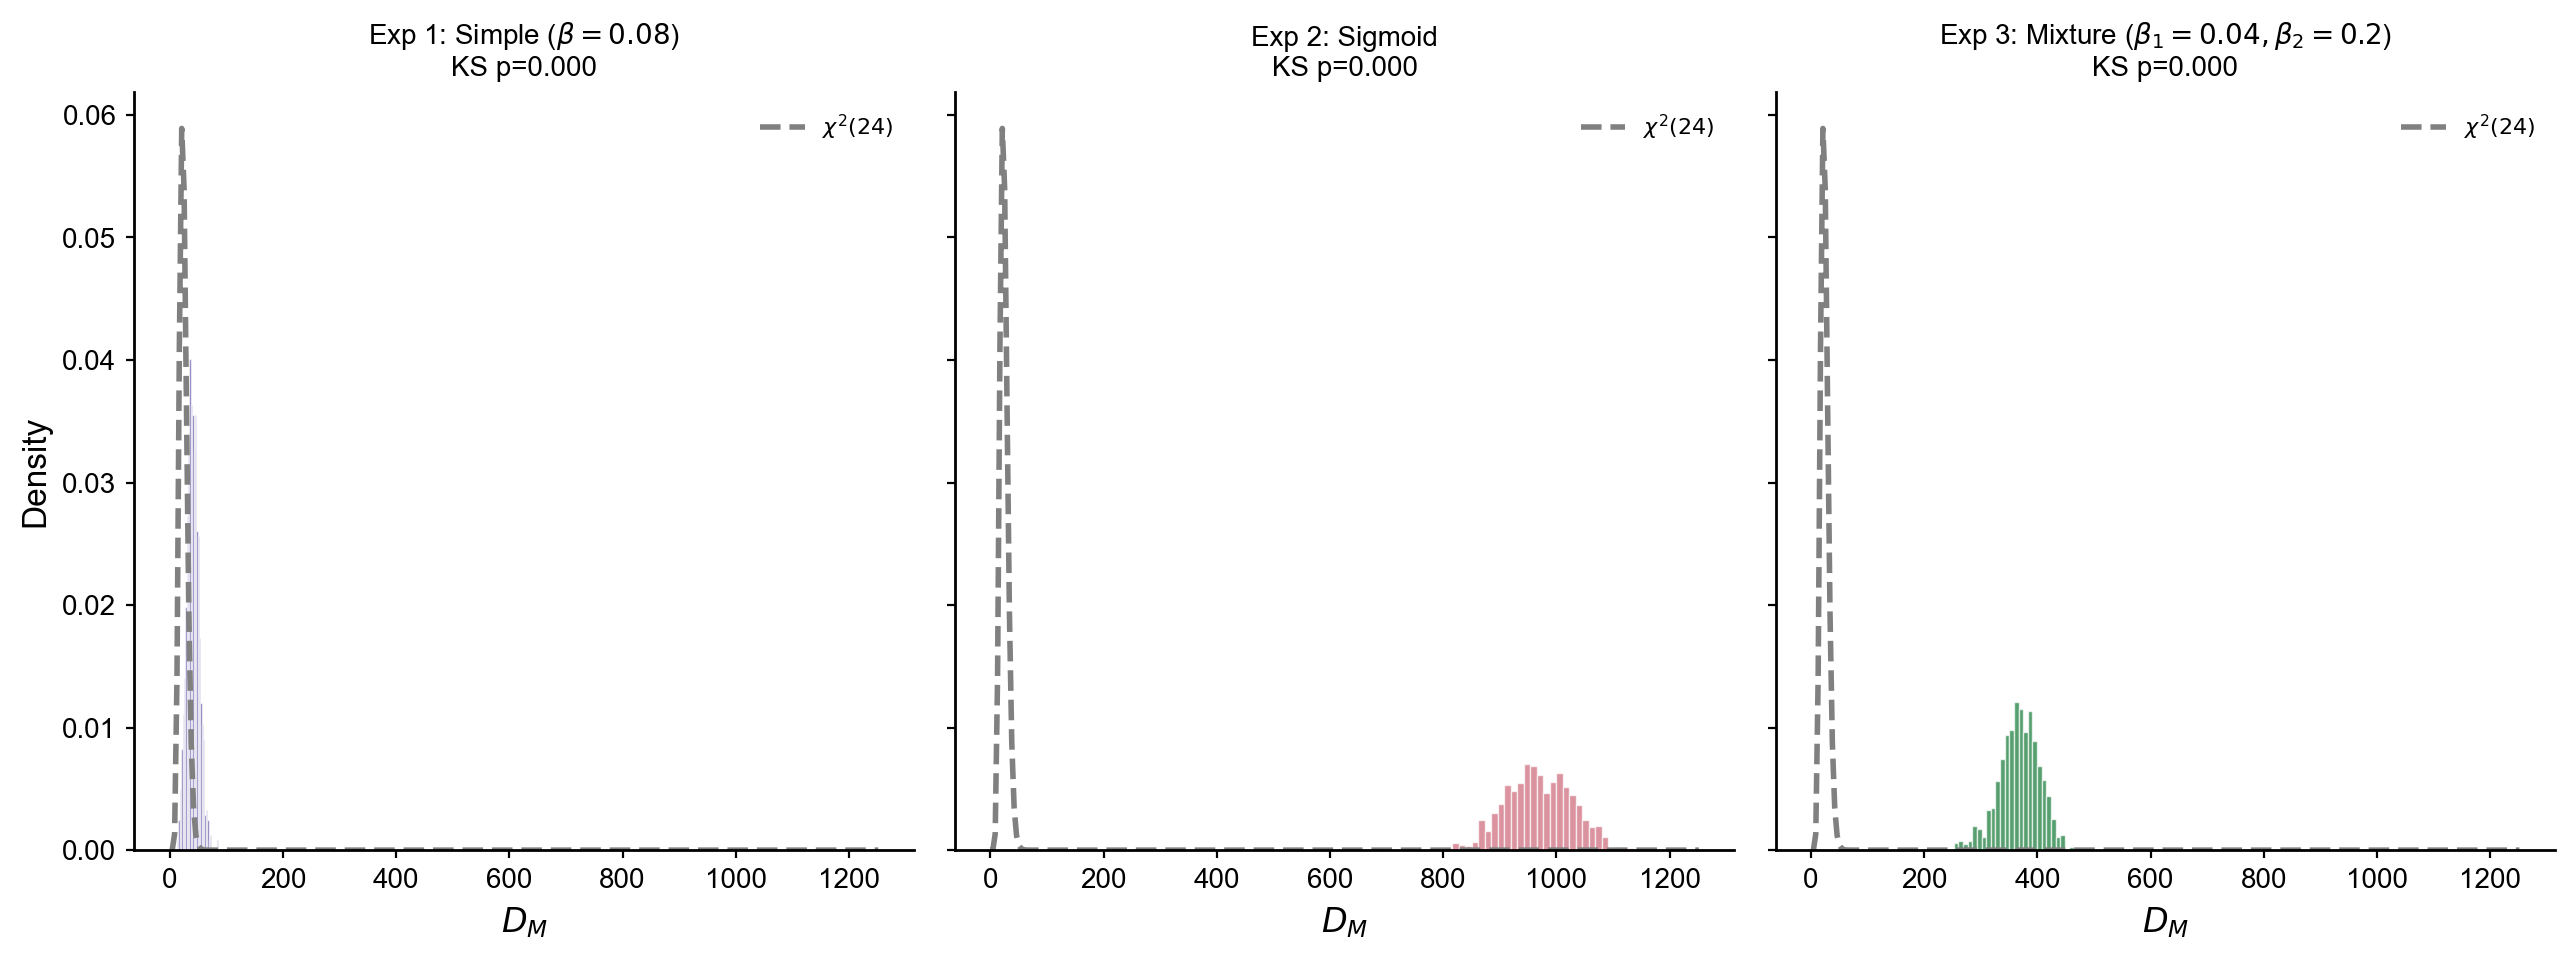

In [7]:
#| label: fig-mahalanobis-dist
#| fig-cap: 'Distribution of Mahalanobis distances from simple contagion reference. Dashed line: theoretical χ²(k−1) density.'
fig, axes = plt.subplots(1, 3, figsize=(WIDTH_DOUBLE * 1.3, HEIGHT_STD), sharey=True)

x_max = max(D_M_exp1.max(), D_M_exp2.max(), D_M_exp3.max()) * 1.1
x_grid = np.linspace(0, x_max, 300)
chi2_pdf = stats.chi2.pdf(x_grid, dof)

configs = [
    (D_M_exp1, PALETTE_MUTED[0], f"Exp 1: Simple ($\\beta={meta['BETA']}$)\nKS p={ks_p1:.3f}"),
    (D_M_exp2, PALETTE_MUTED[6], f"Exp 2: Sigmoid\nKS p={ks_p2:.3f}"),
    (D_M_exp3, PALETTE_MUTED[3], f"Exp 3: Mixture ($\\beta_1={meta['BETA_1']}, \\beta_2={meta['BETA_2']}$)\nKS p={ks_p3:.3f}"),
]

for ax, (D_M, color, title) in zip(axes, configs):
    ax.hist(D_M, bins=30, density=True, alpha=0.7, color=color, edgecolor="white", linewidth=0.5)
    ax.plot(x_grid, chi2_pdf, "--", color="gray", linewidth=2, label=f"$\\chi^2({dof})$")
    ax.set_xlabel("$D_M$")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Density")
plt.tight_layout()
plt.show()

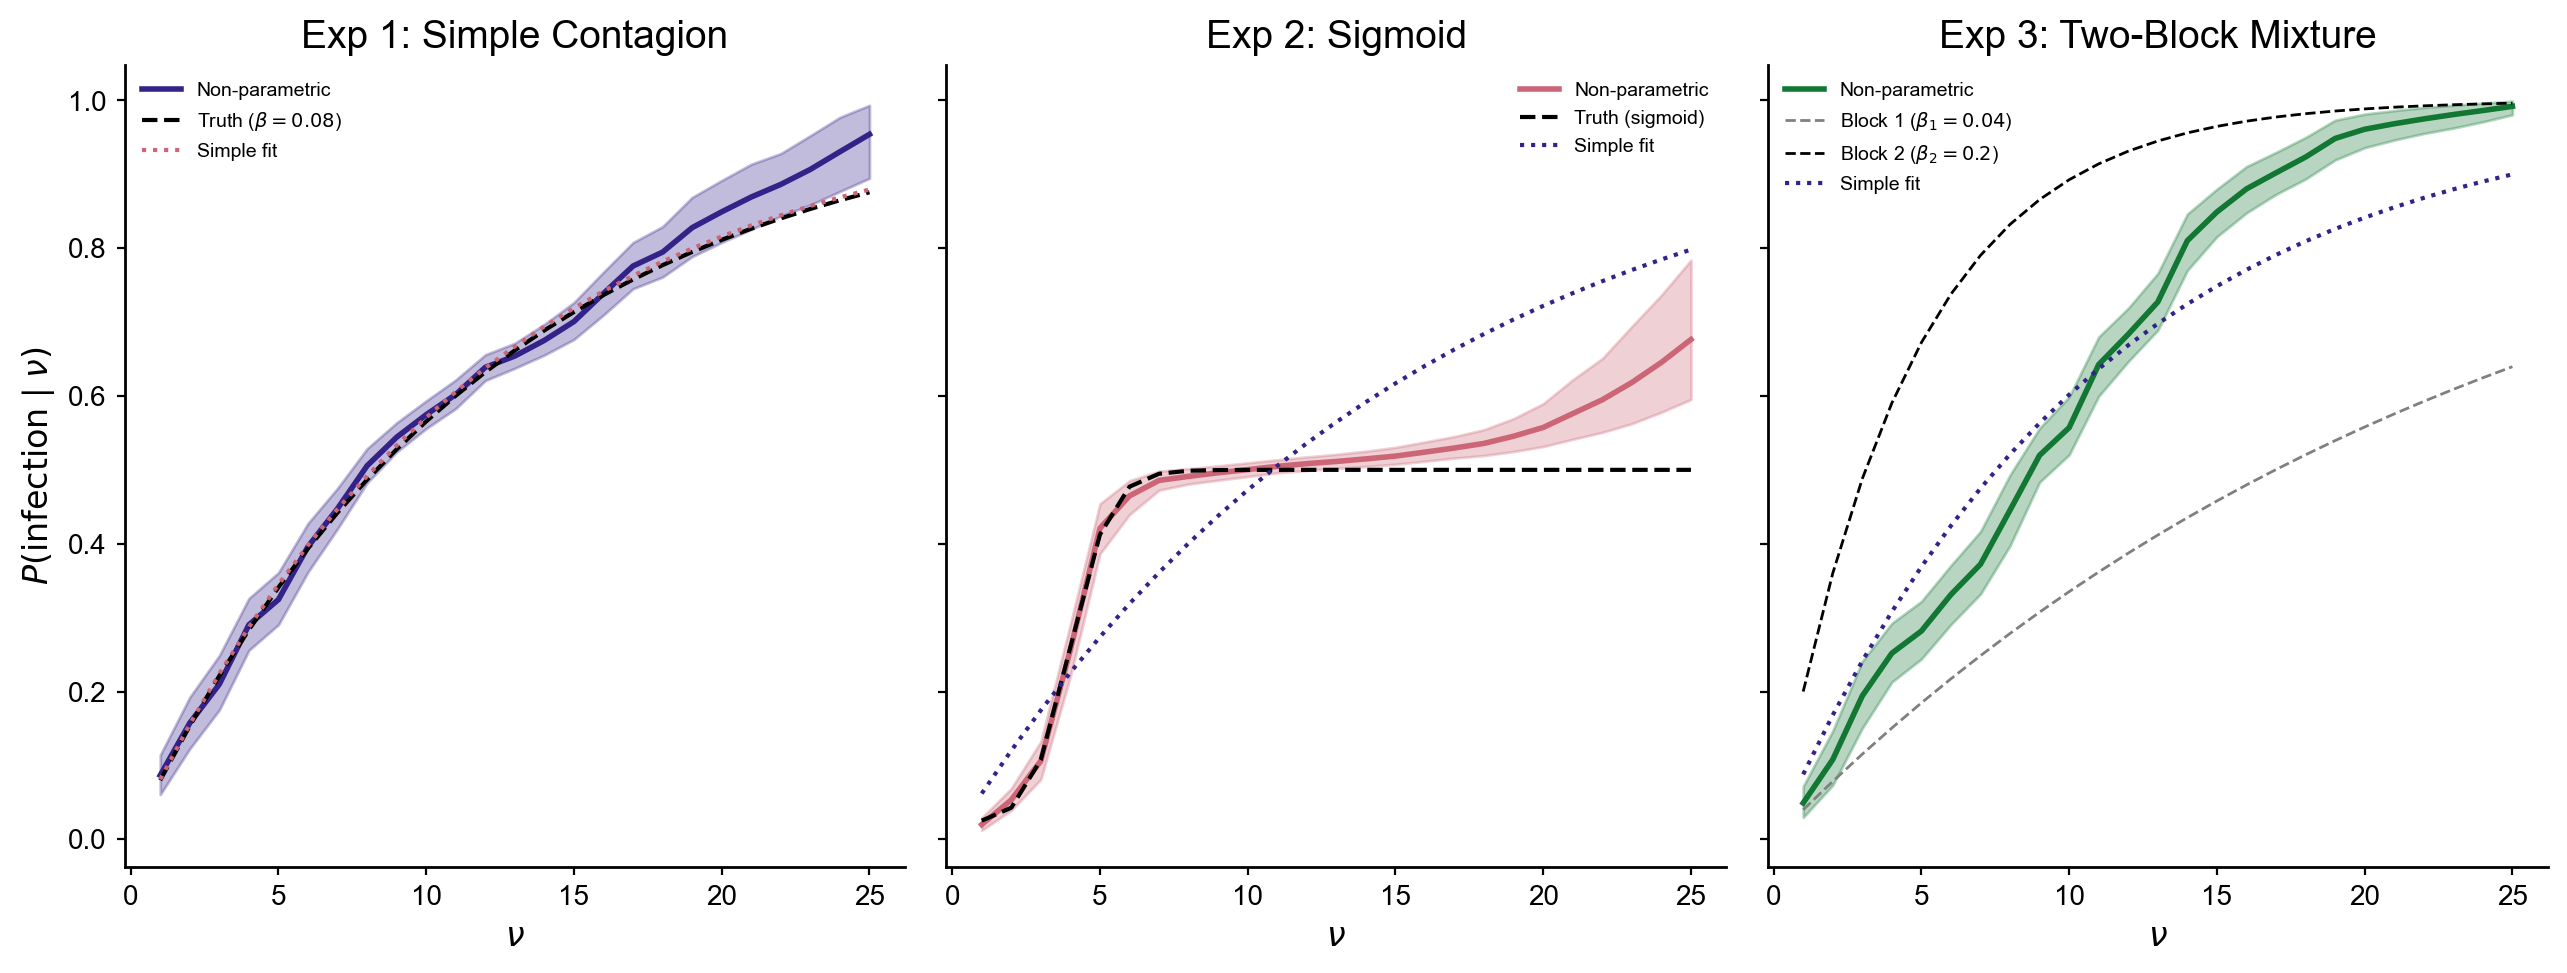

In [8]:
#| label: fig-kernels
#| fig-cap: Posterior kernel modes (non-parametric, shaded 90% CI) vs. ground truth kernels.
fig, axes = plt.subplots(1, 3, figsize=(WIDTH_DOUBLE * 1.3, HEIGHT_STD), sharey=True)

# Ground truth kernels
gt_simple = 1.0 - (1.0 - meta["BETA"]) ** nu
gt_sigmoid = meta["RHO_L"] + (meta["RHO_H"] - meta["RHO_L"]) / (1.0 + np.exp(-meta["W"] * (nu - meta["K0"])))
gt_b1 = 1.0 - (1.0 - meta["BETA_1"]) ** nu
gt_b2 = 1.0 - (1.0 - meta["BETA_2"]) ** nu

# Experiment 1
mu_mean1 = mu_np_exp1.mean(axis=0)
mu_lo1, mu_hi1 = np.percentile(mu_np_exp1, 5, axis=0), np.percentile(mu_np_exp1, 95, axis=0)
axes[0].fill_between(nu, mu_lo1, mu_hi1, alpha=0.3, color=PALETTE_MUTED[0])
axes[0].plot(nu, mu_mean1, "-", color=PALETTE_MUTED[0], linewidth=2, label="Non-parametric")
axes[0].plot(nu, gt_simple, "--", color="black", linewidth=1.5, label=f"Truth ($\\beta={meta['BETA']}$)")
axes[0].plot(nu, mu_sc_exp1, ":", color=PALETTE_MUTED[6], linewidth=1.5, label="Simple fit")
axes[0].set_xlabel("$\\nu$")
axes[0].set_ylabel("$P(\\mathrm{infection} \\mid \\nu)$")
axes[0].set_title("Exp 1: Simple Contagion")
axes[0].legend(fontsize=7)

# Experiment 2
mu_mean2 = mu_np_exp2.mean(axis=0)
mu_lo2, mu_hi2 = np.percentile(mu_np_exp2, 5, axis=0), np.percentile(mu_np_exp2, 95, axis=0)
axes[1].fill_between(nu, mu_lo2, mu_hi2, alpha=0.3, color=PALETTE_MUTED[6])
axes[1].plot(nu, mu_mean2, "-", color=PALETTE_MUTED[6], linewidth=2, label="Non-parametric")
axes[1].plot(nu, gt_sigmoid, "--", color="black", linewidth=1.5, label="Truth (sigmoid)")
axes[1].plot(nu, mu_sc_exp2, ":", color=PALETTE_MUTED[0], linewidth=1.5, label="Simple fit")
axes[1].set_xlabel("$\\nu$")
axes[1].set_title("Exp 2: Sigmoid")
axes[1].legend(fontsize=7)

# Experiment 3
mu_mean3 = mu_np_exp3.mean(axis=0)
mu_lo3, mu_hi3 = np.percentile(mu_np_exp3, 5, axis=0), np.percentile(mu_np_exp3, 95, axis=0)
axes[2].fill_between(nu, mu_lo3, mu_hi3, alpha=0.3, color=PALETTE_MUTED[3])
axes[2].plot(nu, mu_mean3, "-", color=PALETTE_MUTED[3], linewidth=2, label="Non-parametric")
axes[2].plot(nu, gt_b1, "--", color="gray", linewidth=1, label=f"Block 1 ($\\beta_1={meta['BETA_1']}$)")
axes[2].plot(nu, gt_b2, "--", color="black", linewidth=1, label=f"Block 2 ($\\beta_2={meta['BETA_2']}$)")
axes[2].plot(nu, mu_sc_exp3, ":", color=PALETTE_MUTED[0], linewidth=1.5, label="Simple fit")
axes[2].set_xlabel("$\\nu$")
axes[2].set_title("Exp 3: Two-Block Mixture")
axes[2].legend(fontsize=7)

plt.tight_layout()
plt.show()

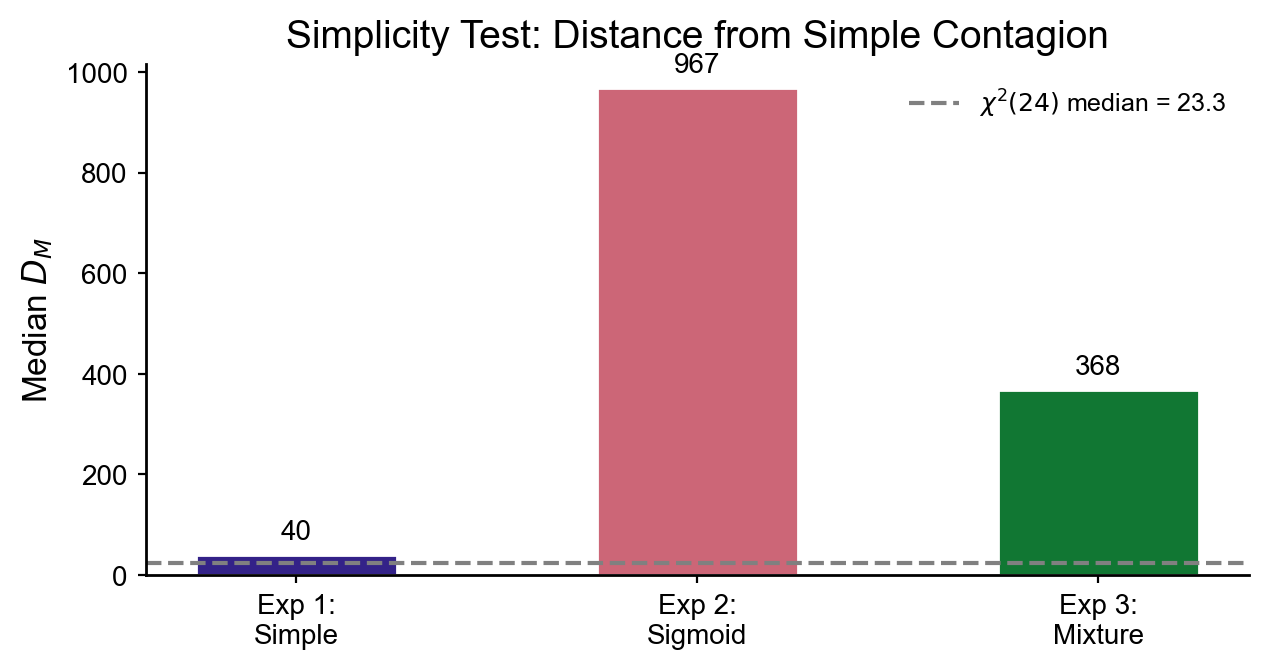

In [9]:
#| label: fig-test-summary
#| fig-cap: 'Simplicity test: median Mahalanobis distance for each experiment.'
fig, ax = plt.subplots(figsize=(WIDTH_SINGLE, HEIGHT_STD * 0.7))

experiments = ["Exp 1:\nSimple", "Exp 2:\nSigmoid", "Exp 3:\nMixture"]
medians = [np.median(D_M_exp1), np.median(D_M_exp2), np.median(D_M_exp3)]
colors = [PALETTE_MUTED[0], PALETTE_MUTED[6], PALETTE_MUTED[3]]

bars = ax.bar(experiments, medians, color=colors, edgecolor="white", width=0.5)

# Reference: chi2 median
chi2_median = stats.chi2.median(dof)
ax.axhline(y=chi2_median, color="gray", linewidth=1.5, linestyle="--", label=f"$\\chi^2({dof})$ median = {chi2_median:.1f}")

for bar, m in zip(bars, medians):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(medians)*0.02,
            f"{m:.0f}", ha="center", va="bottom", fontsize=10)

ax.set_ylabel("Median $D_M$")
ax.set_title("Simplicity Test: Distance from Simple Contagion")
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

In [10]:
#| label: tbl-summary
summary = pd.DataFrame({
    "Experiment": ["1: Simple", "2: Sigmoid", "3: Mixture"],
    "Ground Truth": [
        f"β={meta['BETA']}",
        f"ρ_l={meta['RHO_L']}, ρ_h={meta['RHO_H']}",
        f"β₁={meta['BETA_1']}, β₂={meta['BETA_2']}"
    ],
    "ρ̂ (simple fit)": [f"{rho_exp1.mean():.4f}", f"{rho_exp2.mean():.4f}", f"{rho_exp3.mean():.4f}"],
    "Median D_M": [f"{np.median(D_M_exp1):.1f}", f"{np.median(D_M_exp2):.1f}", f"{np.median(D_M_exp3):.1f}"],
    "KS Statistic": [f"{ks_stat1:.4f}", f"{ks_stat2:.4f}", f"{ks_stat3:.4f}"],
    "KS p-value": [f"{ks_p1:.4f}", f"{ks_p2:.4f}", f"{ks_p3:.4f}"],
    "Reject H₀": [
        "No" if ks_p1 > 0.05 else "Yes",
        "No" if ks_p2 > 0.05 else "Yes",
        "No" if ks_p3 > 0.05 else "Yes",
    ],
})
summary

,Experiment,Ground Truth,ρ̂ (simple fit),Median D_M,KS Statistic,KS p-value,Reject H₀
0,1: Simple,β=0.08,0.0811,40.2,0.6637,0.0000,Yes
1,2: Sigmoid,"ρ_l=0.02, ρ_h=0.5",0.0620,967.2,1.0000,0.0000,Yes
2,3: Mixture,"β₁=0.04, β₂=0.2",0.0879,368.5,1.0000,0.0000,Yes
